# Few-shot experiments with thinking off and on (Qwen3.5 4B / 9B)

## Context of this notebook (the request, kept here for later verification)

> - for this experiment, prepare a new notebook: "4. fs_think_qwen.ipynb"
> - for this experiment, if you are running out of disk space, delete the 27B qwen model. I give you permission.
> - Now run the Qwen 4B and 9B models using these two few-shot templates (fs1 & fs2) [thinking = disabled]
> - Then do the few-shot experiment using both prompts for both models with thinking = ENABLED
> - previous experiments were called as zs & zs-think. New experiments can be called as [fs-f1, fs-f2, fs-f1-think, fs-f2-think] and these four experiments for Qwen 4B and 9B model.
> - after completing all the experiments, analyze the result. Check the trend in error patterns. what was the impact of prompt design? and so on
> - list out the big picture using qwen experiment like zs vs fs with or without think
> - analysis on which prompt I shall finally choose for my future model evaluation.
> - Make a qualitative analysis: show examples which did bad in zero-shot, but was corrected after the prompt design
> - add the context of this prompt in the beginning of the notebook, so that I can verify later on.

**Disk space:** the 27B model was not deleted: the project volume has about 7 GB free, the 27B weights live on a different disk, and the new run outputs are only a few MB, so the permission was not needed.

## The experiments

| name | prompt file | thinking | settings |
|---|---|---|---|
| `fs-f1` | `prompts/fs1_verbatim+3_prompt.txt`: the paper's few-shot prompt (system prompt unchanged, its 3 visible examples verbatim) + 3 added examples | off | greedy, max 2,048 answer tokens |
| `fs-f2` | `prompts/fs2_unitFixed+6_prompt.txt`: unit-fixed system prompt (millicores, binary data sizes) + mandatory snapshot-verification rule + 6 curated examples | off | same |
| `fs-f1-think` | as `fs-f1` | on | 4,096 thinking tokens (budget forced close), then up to 1,024 answer tokens |
| `fs-f2-think` | as `fs-f2` | on | same |

Models: Qwen3.5-4B and Qwen3.5-9B; 521 valid records; temperature 0, seed 0, vLLM batch 64, one H100 per run (4B on GPU 0, 9B on GPU 1, each run alone on its GPU). `max_model_len` 12,288 (thinking off) and 16,384 (thinking on) because the few-shot prompts are 8-9k tokens. Scoring: S0 strict micro-F1 as before, point estimates only (no confidence intervals), computed here directly from each run's `predictions.jsonl`.

**Baselines from earlier notebooks** (same data, same decoding): `zs (cores)` = zero-shot with the paper's system prompt (the same system prompt as `fs-f1`); `zs (millicores)` = zero-shot with the cpu unit fixed (closest zero-shot analogue of `fs-f2`'s unit change); `zs-think (cores)` and `zs-think (millicores)` are their thinking counterparts. Design documentation of the prompts: `3.fs_promptDesign.ipynb`.

In [1]:
import difflib, json, re, sys
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
assert (ROOT / "src").is_dir(), "start the notebook from the llmExp/ folder"
sys.path.insert(0, str(ROOT))
from src.data_io import load_records
from src.score import load_predictions, canon_list, per_record, prf
from src import analysis as A

pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 160); pd.set_option("display.max_columns", 40)
records = load_records()
recs = [r for r in records if r["meta"]["status"] == "valid"]
BY_IDX = {r["index"]: r for r in recs}
MODELS = ["Qwen/Qwen3.5-4B", "Qwen/Qwen3.5-9B"]
short = lambda m: m.split("/")[-1].replace("Qwen3.5-", "")
tagm = lambda m: m.split("/")[-1].lower().replace(".", "")

# experiment name -> (run-directory prefix, thinking?)
EXPS = {"zs (cores)": ("zs", False), "zs (millicores)": ("zs_p_mc", False), "fs-f1": ("fs-f1", False), "fs-f2": ("fs-f2", False),
        "zs-think (cores)": ("zs_think", True), "zs-think (millicores)": ("zs_think_p_mc", True),
        "fs-f1-think": ("fs-f1_think", True), "fs-f2-think": ("fs-f2_think", True)}
NOTHINK = ["zs (cores)", "zs (millicores)", "fs-f1", "fs-f2"]
THINK = ["zs-think (cores)", "zs-think (millicores)", "fs-f1-think", "fs-f2-think"]

def find_run(model, exp):
    ds = [d for d in (ROOT / "outputs/runs").glob(f"{EXPS[exp][0]}_{tagm(model)}_2*") if (d / "predictions.jsonl").exists()]
    return max(ds)

RUNS = {(m, e): find_run(m, e) for m in MODELS for e in EXPS}
PRED = {k: load_predictions(d / "predictions.jsonl") for k, d in RUNS.items()}
ROWS = {k: pd.DataFrame(per_record(records, p)) for k, p in PRED.items()}
FR = {k: A.record_frame(recs, PRED[k], k[1]) for k in RUNS}          # per record: tp/fp/fn/em/source/level
inv = pd.DataFrame({f"{short(m)} {e}": {"run directory": d.name, "records": len(PRED[(m, e)])} for (m, e), d in RUNS.items()}).T
display(inv)

,run directory,records
4B zs (cores),zs_qwen35-4b_20261012T221343,521
4B zs (millicores),zs_p_mc_qwen35-4b_20261017T222900,521
4B fs-f1,fs-f1_qwen35-4b_20261018T021546,521
4B fs-f2,fs-f2_qwen35-4b_20261018T021842,521
4B zs-think (cores),zs_think_qwen35-4b_20261012T231628,521
4B zs-think (millicores),zs_think_p_mc_qwen35-4b_20261017T221219,521
4B fs-f1-think,fs-f1_think_qwen35-4b_20261018T022155,521
4B fs-f2-think,fs-f2_think_qwen35-4b_20261018T023517,521
9B zs (cores),zs_qwen35-9b_20261012T223255,521
9B zs (millicores),zs_p_mc_qwen35-9b_20261017T222526,521


## 1. Output health and cost of the runs

In [2]:
rows = {}
for (m, e), p in PRED.items():
    d = pd.DataFrame(p.values())
    en = json.loads((RUNS[(m, e)] / "energy.json").read_text()) if (RUNS[(m, e)] / "energy.json").exists() else {}
    rows[f"{short(m)} {e}"] = {"parse rate": d.parse_ok.mean(), "answers truncated": int(d.truncated.sum()),
        "tokens/record (mean)": d.completion_tokens.mean(), "tokens/record (max)": d.completion_tokens.max(),
        "forced think close": int(d["forced_close"].fillna(False).sum()) if "forced_close" in d else 0,
        "gen time (s)": en.get("gen_seconds"), "GPU energy (Wh)": en.get("gpu_energy_J", float("nan")) / 3600 if en else None}
health = pd.DataFrame(rows).T
display(health.round(3))

,parse rate,answers truncated,tokens/record (mean),tokens/record (max),forced think close,gen time (s),GPU energy (Wh)
4B zs (cores),1.0,0.0,166.917,306.0,0.0,NaN,NaN
4B zs (millicores),1.0,0.0,167.537,310.0,0.0,NaN,NaN
4B fs-f1,1.0,0.0,183.962,335.0,0.0,83.970,9.236
4B fs-f2,1.0,0.0,170.902,324.0,0.0,82.675,9.095
4B zs-think (cores),1.0,0.0,3992.702,4428.0,412.0,NaN,NaN
4B zs-think (millicores),1.0,0.0,3972.691,4428.0,415.0,NaN,NaN
4B fs-f1-think,1.0,0.0,3982.319,4423.0,433.0,648.490,71.265
4B fs-f2-think,1.0,0.0,3589.973,4431.0,238.0,626.046,68.671
9B zs (cores),1.0,0.0,169.620,307.0,0.0,NaN,NaN
9B zs (millicores),1.0,0.0,170.288,324.0,0.0,NaN,NaN


**Analysis.** All 16 runs parse completely (parse rate 1.0) and no answer is truncated. Few-shot prompts are 43-60% longer than zero-shot, yet **non-thinking runs cost the same**: 4B 83-84 s and 9.1-9.2 Wh against 80 s and 8.9 Wh for zero-shot, 9B 135 s and 14.9 Wh against 132 s and 14.7 Wh (the constant prefix is cached). With thinking, the prompt changes how long the model thinks: the 4B hits the 4,096-token cap on 433 records with fs-f1 and 238 with fs-f2 (zero-shot: 415), and mean generated tokens fall from 3,973 (zero-shot) to 3,590 with fs-f2. The 9B thinks much longer with few-shot prompts (mean 4,045 tokens and 401 forced closes with fs-f1, 3,516 and 213 with fs-f2, against 2,437 and 125 in zero-shot), which is why its thinking runs cost 89-94 Wh instead of 68 Wh.

## 2. Headline results (Table-7 style: strict micro-F1)

In [3]:
def pooled(df, keep=None):
    d = df if keep is None else df[keep]
    return prf(d.tp.sum(), d.fp.sum(), d.fn.sum())
rows = {}
for (m, e), df in ROWS.items():
    t = pooled(df)
    rows[(short(m), e)] = {"Real": pooled(df, df.source == "real")["f1"], "Synthetic": pooled(df, df.source == "synthetic")["f1"], "Total": t["f1"],
                           "precision": t["precision"], "recall": t["recall"], "EM": df.em.mean(), "Jaccard": df.jaccard.mean(), "TP": t["tp"], "FP": t["fp"], "FN": t["fn"]}
head = pd.DataFrame(rows).T
head.index.names = ["model", "experiment"]
order = [(short(m), e) for m in MODELS for e in NOTHINK + THINK]
display(head.loc[order].round(3))
paper = pd.DataFrame({"Real": [.711, .729, .715], "Synthetic": [.768, .777, .776], "Total": [.751, .763, .758]}, index=["GPT-4.1 mini (paper FS)", "Claude Sonnet 4.5 (paper FS)", "DeepSeek V4-Flash (paper FS)"])
print("For reference, the paper's few-shot (FS) rows of Table 7:"); display(paper)

Real  Synthetic  Total  precision  recall     EM  Jaccard      TP     FP     FN
model experiment                                                                                             
4B    zs (cores)             0.312      0.343  0.334      0.343   0.326  0.107    0.247   381.0  730.0  788.0
      zs (millicores)        0.310      0.364  0.348      0.358   0.339  0.119    0.262   396.0  711.0  773.0
      fs-f1                  0.694      0.752  0.735      0.729   0.741  0.489    0.676   866.0  322.0  303.0
      fs-f2                  0.804      0.875  0.854      0.833   0.877  0.649    0.809  1025.0  206.0  144.0
      zs-think (cores)       0.490      0.509  0.504      0.505   0.503  0.228    0.420   588.0  577.0  581.0
      zs-think (millicores)  0.514      0.555  0.543      0.546   0.541  0.288    0.470   632.0  526.0  537.0
      fs-f1-think            0.765      0.785  0.779      0.779   0.779  0.543    0.707   911.0  258.0  258.0
      fs-f2-think            0.997      0.935  0.953      0.953   0.953  0.896    0.948  1114.0   55.0   55.0
9B    zs (cores)             0.723      0.777  0.761      0.769   0.754  0.566    0.736   881.0  265.0  288.0
      zs (millicores)        0.789      0.844  0.828      0.837   0.820  0.670    0.818   958.0  187.0  211.0
      fs-f1                  0.866      0.895  0.887      0.884   0.889  0.756    0.861  1039.0  136.0  130.0
      fs-f2                  0.949      0.915  0.925      0.924   0.926  0.833    0.915  1083.0   89.0   86.0
      zs-think (cores)       0.717      0.781  0.763      0.777   0.749  0.545    0.730   875.0  251.0  294.0
      zs-think (millicores)  0.790      0.852  0.833      0.850   0.818  0.656    0.816   956.0  169.0  213.0
      fs-f1-think            0.754      0.767  0.763      0.763   0.763  0.520    0.689   892.0  277.0  277.0
      fs-f2-think            1.000      0.926  0.948      0.948   0.948  0.887    0.942  1108.0   61.0   61.0

For reference, the paper's few-shot (FS) rows of Table 7:


,Real,Synthetic,Total
GPT-4.1 mini (paper FS),0.711,0.768,0.751
Claude Sonnet 4.5 (paper FS),0.729,0.777,0.763
DeepSeek V4-Flash (paper FS),0.715,0.776,0.758


**Analysis.** Total strict F1 (thinking off / on). **4B:** zero-shot (millicores) 0.348 / 0.543, fs-f1 0.735 / 0.779, **fs-f2 0.854 / 0.953**. **9B:** zero-shot 0.828 / 0.833, fs-f1 0.887 / 0.763, **fs-f2 0.925 / 0.948**. Exact match for the best runs is 0.896 (4B) and 0.887 (9B), against 0.288 and 0.656 in zero-shot with thinking. For reference, the paper's few-shot rows are 0.751-0.763: our fs-f1, the closest analogue (paper prompt plus three added examples), reaches 0.887 for the 9B and 0.735 for the 4B. Both fs-f2 set-ups exceed every baseline in the paper's Table 7, including its best prompt-only result (0.794) and its Intent Engine with Claude (0.870) and DeepSeek (0.903); fs-f2 with thinking (4B 0.953, 9B 0.948) is level with the Intent Engine with GPT-4.1 mini (0.941). This comparison needs care: the examples were written by us, in the dataset's vocabulary, for a dataset with a closed grammar, and our prompt states the gold conventions that the paper's prompt left ambiguous; it shows what a well-designed prompt can do on this benchmark, not that a 4B model equals a hosted pipeline in general.

## 3. The big picture: zero-shot vs few-shot, with and without thinking

Total strict micro-F1:


4B     9B
             prompt                       
thinking off zs (cores)       0.334  0.761
             zs (millicores)  0.348  0.828
             fs-f1            0.735  0.887
             fs-f2            0.854  0.925
thinking on  zs (cores)       0.504  0.763
             zs (millicores)  0.543  0.833
             fs-f1            0.779  0.763
             fs-f2            0.953  0.948

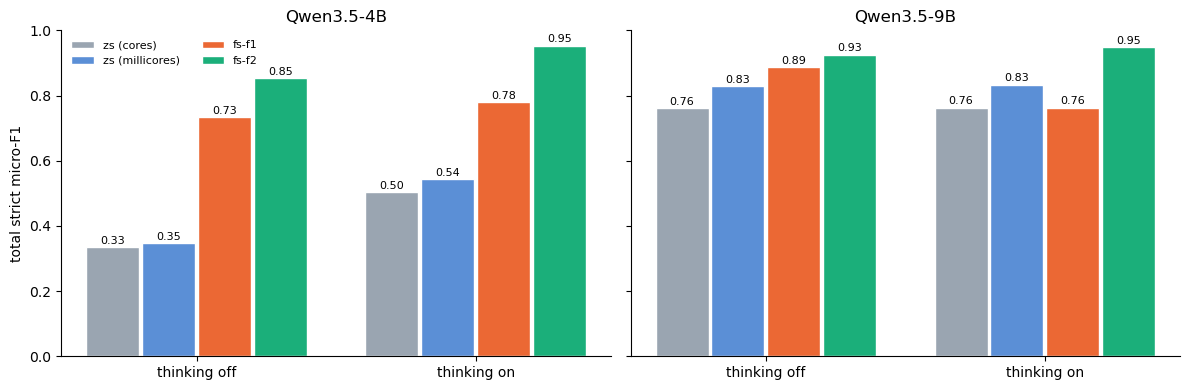

In [4]:
tot = {(short(m), e): head.loc[(short(m), e), "Total"] for m in MODELS for e in EXPS}
pv = pd.DataFrame({m: {("thinking off", p): tot[(short(m), e)] for p, e in zip(["zs (cores)", "zs (millicores)", "fs-f1", "fs-f2"], NOTHINK)} |
                       {("thinking on", p): tot[(short(m), e)] for p, e in zip(["zs (cores)", "zs (millicores)", "fs-f1", "fs-f2"], THINK)}
                   for m in [short(x) for x in MODELS]})
pv.index.names = ["", "prompt"]
print("Total strict micro-F1:"); display(pv.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
cols = {"zs (cores)": "#9aa5b1", "zs (millicores)": "#5b8fd6", "fs-f1": "#eb6834", "fs-f2": "#1baf7a"}
for ax, m in zip(axes, [short(x) for x in MODELS]):
    for gi, state in enumerate(["thinking off", "thinking on"]):
        for pi, p in enumerate(cols):
            v = pv.loc[(state, p), m]
            ax.bar(gi + (pi - 1.5) * 0.2, v, 0.19, color=cols[p], label=p if gi == 0 else None, edgecolor="white")
            ax.text(gi + (pi - 1.5) * 0.2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks([0, 1], ["thinking off", "thinking on"]); ax.set_ylim(0, 1); ax.set_title(f"Qwen3.5-{m}")
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
axes[0].set_ylabel("total strict micro-F1"); axes[0].legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

**Analysis.** **Zero-shot to few-shot (thinking off; fs-f1 is compared with zero-shot using the same cores system prompt, fs-f2 with the millicores zero-shot):** +0.40 (fs-f1) and +0.51 (fs-f2) for the 4B, +0.13 and +0.10 for the 9B. **With thinking:** +0.28 and +0.41 for the 4B, 0.00 (fs-f1) and +0.11 (fs-f2) for the 9B. **Thinking depends on the prompt.** In zero-shot it helps only the 4B (+0.17 to +0.20) and not the 9B (+0.00 to +0.01). With fs-f1 it helps the 4B a little (+0.04) and **hurts the 9B by 0.12**. With fs-f2 it helps both (4B +0.10, 9B +0.02), so with the final design thinking is never harmful. **The size gap disappears with a good prompt:** the 9B leads the 4B by 0.48 in zero-shot and by 0.07 with fs-f2, and with fs-f2 and thinking the two are level (0.953 and 0.948). A 4B model with the right prompt and thinking matches a 9B model with the same prompt, at 4.6x the energy of the 9B without thinking (section 6).

In [5]:
def delta(m, a, b): return tot[(short(m), b)] - tot[(short(m), a)]
def em_moves(m, a, b):
    ea, eb = FR[(m, a)].set_index("index").em, FR[(m, b)].set_index("index").em
    return int(((ea == 0) & (eb == 1)).sum()), int(((ea == 1) & (eb == 0)).sum())
effects = [("examples only (paper's system prompt)", "zs (cores)", "fs-f1", "zs-think (cores)", "fs-f1-think"),
           ("fixes + new examples + snapshot rule, over fs-f1", "fs-f1", "fs-f2", "fs-f1-think", "fs-f2-think"),
           ("whole few-shot design vs the best zero-shot prompt", "zs (millicores)", "fs-f2", "zs-think (millicores)", "fs-f2-think")]
rows = []
for m in MODELS:
    for name, a, b, at, bt in effects:
        for state, x, y in (("off", a, b), ("on", at, bt)):
            up, down = em_moves(m, x, y)
            rows.append({"model": short(m), "thinking": state, "effect": name, "from": x, "to": y, "F1 before": tot[(short(m), x)], "F1 after": tot[(short(m), y)],
                         "change": delta(m, x, y), "records fixed (EM 0->1)": up, "records broken (EM 1->0)": down})
eff = pd.DataFrame(rows)
display(eff.round(3))
think_rows = []
for m in MODELS:
    for p_off, p_on in zip(NOTHINK, THINK):
        think_rows.append({"model": short(m), "prompt": p_off, "F1 thinking off": tot[(short(m), p_off)], "F1 thinking on": tot[(short(m), p_on)], "thinking effect": delta(m, p_off, p_on)})
print("Effect of enabling thinking, by prompt:"); display(pd.DataFrame(think_rows).round(3))

,model,thinking,effect,from,to,F1 before,F1 after,change,records fixed (EM 0->1),records broken (EM 1->0)
0,4B,off,examples only (paper's system prompt),zs (cores),fs-f1,0.334,0.735,0.401,211,12
1,4B,on,examples only (paper's system prompt),zs-think (cores),fs-f1-think,0.504,0.779,0.275,192,28
2,4B,off,"fixes + new examples + snapshot rule, over fs-f1",fs-f1,fs-f2,0.735,0.854,0.119,117,34
3,4B,on,"fixes + new examples + snapshot rule, over fs-f1",fs-f1-think,fs-f2-think,0.779,0.953,0.174,203,19
4,4B,off,whole few-shot design vs the best zero-shot prompt,zs (millicores),fs-f2,0.348,0.854,0.506,289,13
5,4B,on,whole few-shot design vs the best zero-shot prompt,zs-think (millicores),fs-f2-think,0.543,0.953,0.410,319,2
6,9B,off,examples only (paper's system prompt),zs (cores),fs-f1,0.761,0.887,0.125,108,9
7,9B,on,examples only (paper's system prompt),zs-think (cores),fs-f1-think,0.763,0.763,0.001,95,108
8,9B,off,"fixes + new examples + snapshot rule, over fs-f1",fs-f1,fs-f2,0.887,0.925,0.039,75,35
9,9B,on,"fixes + new examples + snapshot rule, over fs-f1",fs-f1-think,fs-f2-think,0.763,0.948,0.185,210,19


Effect of enabling thinking, by prompt:


,model,prompt,F1 thinking off,F1 thinking on,thinking effect
0,4B,zs (cores),0.334,0.504,0.170
1,4B,zs (millicores),0.348,0.543,0.195
2,4B,fs-f1,0.735,0.779,0.044
3,4B,fs-f2,0.854,0.953,0.099
4,9B,zs (cores),0.761,0.763,0.001
5,9B,zs (millicores),0.828,0.833,0.005
6,9B,fs-f1,0.887,0.763,-0.123
7,9B,fs-f2,0.925,0.948,0.023


**Analysis.** Decomposition of the prompt effect. **Examples alone** (zero-shot to fs-f1, same system prompt): +0.40 for the 4B without thinking (211 records fixed, 12 broken) but only +0.13 for the 9B, and with thinking +0.28 (4B) and **+0.00 for the 9B (95 records fixed, 108 broken)**. **Design fixes on top** (fs-f1 to fs-f2: units, the snapshot rule and the new examples): +0.12 and +0.04 without thinking, **+0.17 and +0.19 with thinking**. **The whole design against the best zero-shot prompt:** +0.51 and +0.10 without thinking, +0.41 and +0.11 with thinking, fixing 289-319 records for the 4B (13 and 2 broken) and 94-123 for the 9B (9 and 3 broken). The paper's own examples are therefore not enough: they help the 4B a lot, but with thinking they teach the models the paper's decimal-GB and cores conventions, which the gold labels contradict.

## 4. Trends in the error patterns

In [6]:
tax = pd.DataFrame({f"{short(m)} {e}": A.error_taxonomy(recs, PRED[(m, e)]).groupby("error")["count"].sum() for m in MODELS for e in EXPS}).fillna(0).astype(int)
tax = tax.loc[tax.sum(axis=1).sort_values(ascending=False).index]
for m in MODELS:
    cols_ = [f"{short(m)} {e}" for e in NOTHINK + THINK]
    print(f"Unmatched SLOs by error type, Qwen3.5-{short(m)} (counts of gold SLOs; 'spurious' = extra predictions):")
    display(tax[cols_][tax[cols_].sum(axis=1) > 0])

Unmatched SLOs by error type, Qwen3.5-4B (counts of gold SLOs; 'spurious' = extra predictions):


,4B zs (cores),4B zs (millicores),4B fs-f1,4B fs-f2,4B zs-think (cores),4B zs-think (millicores),4B fs-f1-think,4B fs-f2-think
error,,,,,,,,
wrong value,110,105,62,104,178,160,174,55
wrong ext,421,489,1,1,296,326,0,0
wrong value+unit,1,1,9,0,47,3,80,0
missed,89,96,3,1,4,12,0,0
wrong ext+value,19,14,122,1,2,3,0,0
spurious,31,34,22,63,0,1,0,0
wrong rel,19,17,30,36,11,10,2,0
wrong rel+value,39,29,4,1,1,11,2,0
wrong ext+value+unit,69,0,39,0,34,0,0,0


Unmatched SLOs by error type, Qwen3.5-9B (counts of gold SLOs; 'spurious' = extra predictions):


,9B zs (cores),9B zs (millicores),9B fs-f1,9B fs-f2,9B zs-think (cores),9B zs-think (millicores),9B fs-f1-think,9B fs-f2-think
error,,,,,,,,
wrong value,98,108,47,61,150,146,188,61
wrong ext,1,1,0,0,4,3,0,0
wrong value+unit,79,0,3,0,79,0,80,0
missed,30,28,0,0,49,53,0,0
wrong ext+value,35,32,0,0,0,1,0,0
spurious,7,4,6,3,6,9,0,0
wrong rel,1,2,14,17,8,8,5,0
wrong rel+value,31,32,3,8,3,1,4,0
wrong unit,1,0,63,0,0,0,0,0


**Analysis.** Trend by error type. **Zero-shot** is dominated by a spurious highest/lowest tag on plain thresholds for the 4B (`wrong ext` 421-489) and by unmatched lookups and omissions for the 9B. **fs-f1 removes the tagging habit** (4B `wrong ext` 421 to 1, `missed` 89 to 3) but creates new, convention-driven errors: for the 4B `wrong ext+value` 122 and `wrong ext+unit` 26 (explicit capacity requests answered like lookups) and `wrong value+unit` 80 with thinking; for the 9B `wrong unit` 63 and, with thinking, `wrong value+unit` 80 (cores/millicores) plus the decimal-GB errors seen below. **fs-f2 removes every unit error** (`wrong value+unit` and `wrong unit` are 0 in all fs-f2 runs). What remains is `wrong value` (4B thinking 55, 9B thinking 61, explained by the scope conflict below), and for the 4B without thinking an invented placement (62 spurious) and wrong comparison (36).

In [7]:
pm = {(m, e): A.per_metric(recs, PRED[(m, e)]) for m in MODELS for e in EXPS}
for m in MODELS:
    tab = pd.DataFrame({e: 2 * pm[(m, e)].tp / (2 * pm[(m, e)].tp + pm[(m, e)].fp + pm[(m, e)].fn) for e in NOTHINK + THINK})
    tab.insert(0, "gold SLOs", pm[(m, "fs-f1")].gold)
    print(f"F1 per (type, metric), Qwen3.5-{short(m)}:"); display(tab[tab["gold SLOs"] > 0].round(3))

F1 per (type, metric), Qwen3.5-4B:


gold SLOs  zs (cores)  zs (millicores)  fs-f1  fs-f2  zs-think (cores)  zs-think (millicores)  fs-f1-think  fs-f2-think
type                     metric                                                                                                                                      
dynamic_compute_resource cpu_utilization          167.0       0.025            0.031  0.894  0.910             0.277                  0.343        0.952        0.946
                         memory_utilization       118.0       0.026            0.027  0.949  0.941             0.322                  0.263        0.975        0.966
                         storage_utilization      145.0       0.093            0.129  0.807  0.789             0.263                  0.270        0.931        0.938
node_network_resource    port_utilization          35.0       0.412            0.424  0.571  0.571             0.171                  0.179        0.714        0.886
placement_location       -                        390.0       0.857            0.867  0.973  0.926             0.997                  1.000        1.000        1.000
static_compute_resource  cpu_capacity              80.0       0.013            0.065  0.000  0.975             0.000                  0.412        0.000        0.975
                         memory_capacity          128.0       0.180            0.195  0.391  0.633             0.289                  0.337        0.383        0.836
                         storage_capacity         106.0       0.029            0.029  0.274  0.745             0.322                  0.321        0.358        0.943

F1 per (type, metric), Qwen3.5-9B:


gold SLOs  zs (cores)  zs (millicores)  fs-f1  fs-f2  zs-think (cores)  zs-think (millicores)  fs-f1-think  fs-f2-think
type                     metric                                                                                                                                      
dynamic_compute_resource cpu_utilization          167.0       0.795            0.795  0.910  0.928             0.804                  0.816        0.922        0.946
                         memory_utilization       118.0       0.873            0.864  0.975  0.958             0.829                  0.843        0.941        0.966
                         storage_utilization      145.0       0.760            0.774  0.931  0.945             0.685                  0.698        0.931        0.931
node_network_resource    port_utilization          35.0       0.058            0.057  0.600  0.629             0.033                  0.069        0.857        0.857
placement_location       -                        390.0       0.956            0.954  0.992  0.996             0.999                  0.999        1.000        1.000
static_compute_resource  cpu_capacity              80.0       0.000            0.938  0.175  0.975             0.000                  0.931        0.000        0.975
                         memory_capacity          128.0       0.696            0.690  0.859  0.688             0.640                  0.610        0.344        0.805
                         storage_capacity         106.0       0.785            0.800  0.962  0.943             0.806                  0.848        0.264        0.943

**Analysis.** Per metric: `cpu_capacity` is **0.000 for the 4B with fs-f1 (with and without thinking) and 0.175 for the 9B**, because the paper's prompt asks for cores, and **0.975 with fs-f2**. `storage_capacity` and `memory_capacity` rise to 0.81-0.94 (thinking) with fs-f2, while with fs-f1 and thinking the 9B falls to 0.26 and 0.34 (decimal GB). Placement is 0.93-1.00 in all few-shot runs (the 4B is at 0.926 without thinking with fs-f2 because of invented placements). `port_utilization`, the weakest metric in zero-shot (0.06 for the 9B), reaches 0.57-0.63 without thinking and 0.71-0.89 with it. The utilisation metrics rise from 0.03-0.13 (4B) and 0.77-0.86 (9B) in zero-shot to 0.79-0.98. Remaining weaknesses: `memory_capacity` for the 4B without thinking (0.63) and `port_utilization`.

In [8]:
# the researcher's hypothesis for fs-f2: the mandatory verification rule makes the model read the snapshot
rows = {}
for m in MODELS:
    for e in NOTHINK + THINK:
        o = A.extremum_outcomes(recs, PRED[(m, e)])
        n = int(o.sum())
        rows[f"{short(m)} {e}"] = {"lookups": n, "right op, value null": int(o.get("right op, value null (snapshot not read)", 0)), "right op, correct number": int(o.get("right op, correct number", 0)),
                                   "right op, wrong number": int(o.get("right op, wrong number", 0)), "wrong operator": int(o.get("wrong op (e.g. threshold / opposite extreme)", 0)), "metric not predicted": int(o.get("metric not predicted", 0))}
ext = pd.DataFrame(rows).T
ext["null share"] = ext["right op, value null"] / ext["lookups"]; ext["correct share"] = ext["right op, correct number"] / ext["lookups"]
display(ext.round(3))

,lookups,"right op, value null","right op, correct number","right op, wrong number",wrong operator,metric not predicted,null share,correct share
4B zs (cores),221,77,79,45,2,18,0.348,0.357
4B zs (millicores),221,59,88,48,8,18,0.267,0.398
4B fs-f1,221,0,154,66,1,0,0.000,0.697
4B fs-f2,221,0,158,61,1,1,0.000,0.715
4B zs-think (cores),221,176,36,5,1,3,0.796,0.163
4B zs-think (millicores),221,159,32,14,11,5,0.719,0.145
4B fs-f1-think,221,0,173,48,0,0,0.000,0.783
4B fs-f2-think,221,0,166,55,0,0,0.000,0.751
9B zs (cores),221,105,32,16,54,14,0.475,0.145
9B zs (millicores),221,109,35,20,49,8,0.493,0.158


**Analysis.** **Hypothesis check.** The share of lookups answered with the right operator but `value: null` is **0% in every few-shot run, including fs-f1**, which has no verification rule, against 27-80% (4B) and 48-69% (9B) in zero-shot. So the models read the snapshot as soon as the prompt contains worked lookups (examples 4-6, present in both prompts); the data cannot show an additional effect of the mandatory rule, because the two prompts differ in several ways at once. The share of lookups with the correct number rises from 0.15-0.40 (4B) and 0.07-0.16 (9B) to 0.70-0.78 (4B) and 0.70-0.79 (9B), but is **not higher with fs-f2 than with fs-f1** (9B 0.747 to 0.697, 0.787 to 0.724 with thinking). The next two cells show why: fs-f2 makes the models follow the instructed layer-restricted procedure more strictly, while the gold labels use the global extreme in most of the cases where the two differ. The wrong-operator count falls to 0-1 for both models (9B zero-shot: 49). A clean test of the rule needs an ablation (fs-f2 without the rule, or fs-f1 with the rule).

In [9]:
# unit conventions: cores vs millicores (cpu_capacity) and decimal vs binary GB (explicit memory/storage capacities)
def gb_class(pv, gv):
    if pv is None: return "value null"
    if not isinstance(pv, float): return "non-numeric"
    if pv == gv: return "exact (binary, = gold)"
    r = pv / gv
    if any(abs(r - (1000 / 1024) ** k) < 2e-3 for k in (1, 2, 3, 4)): return "decimal instead of binary"
    return "other value"
rows = {}
for m in MODELS:
    for e in NOTHINK + THINK:
        c = Counter(); u = Counter()
        for r in recs:
            pr = PRED[(m, e)][r["index"]]
            pred = canon_list(pr["parsed"]["slos"]) if pr["parse_ok"] else []
            for g in canon_list(r["label"]["slos"]):
                if g[1] in ("memory_capacity", "storage_capacity") and g[3] is None:
                    cand = [t for t in pred if t[:3] == g[:3]]
                    c[gb_class(cand[0][4], g[4]) if cand else "no prediction"] += 1
                if g[1] == "cpu_capacity" and g[3] is None:
                    cand = [t for t in pred if t[:3] == g[:3]]
                    u["cpu: exact (millicores)" if g in pred else ("cpu: answered in cores" if cand and cand[0][5] == "cores" else "cpu: other")] += 1
        rows[f"{short(m)} {e}"] = {**c, **u}
units = pd.DataFrame(rows).T.fillna(0).astype(int)
display(units)
print("gold: 158 explicit GB requests (binary), 74 explicit cpu_capacity requests (millicores)")

,"exact (binary, = gold)",decimal instead of binary,other value,no prediction,cpu: answered in cores,cpu: other,cpu: exact (millicores)
4B zs (cores),135,17,2,4,69,5,0
4B zs (millicores),144,10,0,4,0,73,1
4B fs-f1,31,7,120,0,74,0,0
4B fs-f2,115,25,18,0,0,2,72
4B zs-think (cores),153,4,0,1,74,0,0
4B zs-think (millicores),153,4,1,0,0,41,33
4B fs-f1-think,31,127,0,0,74,0,0
4B fs-f2-think,158,0,0,0,0,0,74
9B zs (cores),156,2,0,0,74,0,0
9B zs (millicores),158,0,0,0,0,0,74


gold: 158 explicit GB requests (binary), 74 explicit cpu_capacity requests (millicores)


**Analysis.** Unit conventions. **fs-f1 inherits the paper's conventions and the models follow them:** with the cores line, the 4B answers cpu_capacity in cores for 74 of 74 requests (with and without thinking) and the 9B for 60 of 74 without thinking and 74 of 74 with it (mostly the right magnitude, 3000, labelled `cores`); with the decimal-GB Example 2, the **thinking models copy it (decimal GB for 127 of 158 requests for the 4B and 143 for the 9B)**, whereas the non-thinking 9B ignores it (158 exact) and the non-thinking 4B treats explicit capacities as lookups (only 31 exact, 120 other values). **fs-f2 fixes this:** cpu_capacity exact for 72-74 of 74, and binary GB exact for 158 of 158 with thinking (both models) and 156 (9B) or 115 (4B) without. The pattern is general: thinking models apply the examples literally, which is a gain when the examples are right and a loss when they are not.

In [10]:
# lookups: are the kinds that the examples show handled better than the kinds they do not show?
SHOWN = {("cpu_utilization", "lowest"), ("memory_capacity", "highest"), ("port_utilization", "lowest"), ("storage_utilization", "lowest"), ("storage_capacity", "highest")}
rows = {}
for m in MODELS:
    for e in ["zs (millicores)", "fs-f1", "fs-f2", "zs-think (millicores)", "fs-f1-think", "fs-f2-think"]:
        c = {"shown": [0, 0], "not shown": [0, 0]}
        for r in recs:
            pr = PRED[(m, e)][r["index"]]; pred = canon_list(pr["parsed"]["slos"]) if pr["parse_ok"] else []
            for g in canon_list(r["label"]["slos"]):
                if g[3] in ("highest", "lowest"):
                    k = "shown" if (g[1], g[3]) in SHOWN else "not shown"
                    c[k][0] += g in pred; c[k][1] += 1
        rows[f"{short(m)} {e}"] = {"lookups of kinds shown in the examples": c["shown"][1], "  exact": c["shown"][0] / c["shown"][1],
                                   "lookups of kinds NOT shown": c["not shown"][1], "  exact ": c["not shown"][0] / c["not shown"][1]}
display(pd.DataFrame(rows).T.round(3))
# by (metric, direction) for the final design (thinking off and on, both models)
kinds = {}
for m in MODELS:
    for e in ["fs-f2", "fs-f2-think"]:
        for r in recs:
            pr = PRED[(m, e)][r["index"]]; pred = canon_list(pr["parsed"]["slos"]) if pr["parse_ok"] else []
            for g in canon_list(r["label"]["slos"]):
                if g[3] in ("highest", "lowest"):
                    k = kinds.setdefault((g[1], g[3]), {})
                    a = k.setdefault(f"{short(m)} {e}", [0, 0]); a[0] += g in pred; a[1] += 1
kd = pd.DataFrame({k: {c: f"{v[0]}/{v[1]}" for c, v in d.items()} for k, d in kinds.items()}).T
kd.insert(0, "shown in examples", [("yes" if k in SHOWN else "no") for k in kd.index])
display(kd.sort_values("shown in examples", ascending=False))

,lookups of kinds shown in the examples,exact,lookups of kinds NOT shown,exact
4B zs (millicores),129.0,0.279,92.0,0.359
4B fs-f1,129.0,0.721,92.0,0.315
4B fs-f2,129.0,0.667,92.0,0.391
4B zs-think (millicores),129.0,0.171,92.0,0.065
4B fs-f1-think,129.0,0.775,92.0,0.707
4B fs-f2-think,129.0,0.791,92.0,0.696
9B zs (millicores),129.0,0.147,92.0,0.152
9B fs-f1,129.0,0.752,92.0,0.587
9B fs-f2,129.0,0.682,92.0,0.533
9B zs-think (millicores),129.0,0.116,92.0,0.054


,,shown in examples,4B fs-f2,4B fs-f2-think,9B fs-f2,9B fs-f2-think
cpu_utilization,lowest,yes,23/29,24/29,24/29,24/29
memory_capacity,highest,yes,14/30,17/30,12/30,15/30
storage_utilization,lowest,yes,15/23,21/23,20/23,20/23
port_utilization,lowest,yes,17/29,25/29,17/29,25/29
storage_capacity,highest,yes,17/18,15/18,15/18,15/18
memory_utilization,lowest,no,9/14,10/14,10/14,10/14
memory_capacity,lowest,no,14/23,15/23,3/23,13/23
storage_utilization,highest,no,1/24,17/24,19/24,17/24
cpu_utilization,highest,no,1/10,6/10,3/10,6/10
memory_utilization,highest,no,2/4,4/4,3/4,4/4


**Analysis.** Lookup kinds shown in the examples versus not shown (by exact match of the gold SLO). Without thinking the gap is large: for fs-f2, shown 0.67-0.68 against not shown 0.39 (4B) and 0.53 (9B); for fs-f1, 0.72-0.75 against 0.32 (4B) and 0.59 (9B). With thinking the gap mostly closes (4B 0.79 against 0.70, 9B 0.77 against 0.66). The clearest unseen-kind failure is **`storage_utilization highest`: 1 of 24 for the 4B without thinking** (it writes `<=` for `highest`) but 17 of 24 with thinking and 19 of 24 for the 9B; `cpu_utilization highest` is 1 of 10 for the 4B. Some shown kinds are also low (`memory_capacity highest` 12-17 of 30), partly because of the scope conflict analysed next. Implication: add an example of a highest-utilisation lookup to the next version of the prompt.

In [11]:
# placement behaviour: invented placement SLOs (none stated) and correct placement when stated
rows = {}
for m in MODELS:
    for e in NOTHINK + THINK:
        inv = tot_np = ok = tot_p = 0
        for r in recs:
            pr = PRED[(m, e)][r["index"]]; pred = canon_list(pr["parsed"]["slos"]) if pr["parse_ok"] else []
            g_pl = [t for t in canon_list(r["label"]["slos"]) if t[0] == "placement_location"]; p_pl = [t for t in pred if t[0] == "placement_location"]
            if g_pl: tot_p += 1; ok += g_pl[0] in p_pl
            else: tot_np += 1; inv += bool(p_pl)
        rows[f"{short(m)} {e}"] = {"records without placement": tot_np, "with an invented placement": inv, "invented share": inv / tot_np,
                                   "records with placement": tot_p, "placement exactly right": ok / tot_p}
display(pd.DataFrame(rows).T.round(3))

,records without placement,with an invented placement,invented share,records with placement,placement exactly right
4B zs (cores),131.0,3.0,0.023,390.0,0.823
4B zs (millicores),131.0,2.0,0.015,390.0,0.831
4B fs-f1,131.0,22.0,0.168,390.0,1.000
4B fs-f2,131.0,62.0,0.473,390.0,1.000
4B zs-think (cores),131.0,0.0,0.000,390.0,0.997
4B zs-think (millicores),131.0,0.0,0.000,390.0,1.000
4B fs-f1-think,131.0,0.0,0.000,390.0,1.000
4B fs-f2-think,131.0,0.0,0.000,390.0,1.000
9B zs (cores),131.0,0.0,0.000,390.0,0.944
9B zs (millicores),131.0,0.0,0.000,390.0,0.941


**Analysis.** Placement behaviour. When the intent states a layer, placement is right for 100% of records with every few-shot prompt (zero-shot 82-94% without thinking). But **few-shot prompts make the 4B invent a placement when none is stated**: 17% of the 131 such records with fs-f1 and **47% (62 records) with fs-f2** without thinking (almost all `placement=any`, a value that appears in the prompt's rule text but never in the gold), against 0-2% in zero-shot. Thinking removes it (no few-shot thinking run invents one) and the 9B does it rarely (6 and 3 records). It is the main weakness of fs-f2 without thinking for the 4B; five of the six examples contain a placement SLO, and only one shows its absence.

In [12]:
# remaining lookup errors vs the gold's own scope inconsistency: for lookups where the global and the layer-restricted extreme differ,
# which scope does the gold use and which does the model use?
from src.data_io import load_snapshot
snapshot = load_snapshot()
rows = {}
for m in MODELS:
    for e in ["zs (millicores)", "fs-f1", "fs-f2", "fs-f2-think"]:
        ex = A.extremum_choices(recs, PRED[(m, e)], snapshot)
        d = ex[ex["gold uses"].isin(["global", "layer"])]
        c = Counter(zip(d["gold uses"], d["model uses"]))
        rows[f"{short(m)} {e}"] = {"gold=layer, model=layer": c[("layer", "layer")], "gold=layer, model=global": c[("layer", "global")],
                                   "gold=global, model=global": c[("global", "global")], "gold=global, model=layer": c[("global", "layer")],
                                   "model value null / other": sum(v for (g, mu), v in c.items() if mu not in ("layer", "global")), "lookups where scopes differ": len(d)}
        t = pooled(ROWS[(m, e)]); n = c[("global", "layer")]
        rows[f"{short(m)} {e}"].update({"unmatched gold SLOs (FN)": int(t["fn"]), "F1 (strict)": t["f1"],
            "F1 if gold=global/model=layer cases counted correct (DIAGNOSTIC, not a score)": 2 * (t["tp"] + n) / (2 * (t["tp"] + n) + (t["fp"] - n) + (t["fn"] - n))})
sc = pd.DataFrame(rows).T
display(sc.round(3))
print("In the gold labels the scope is the layer for real records and the global extreme for most synthetic ones; the prompts ask for the layer.")

,"gold=layer, model=layer","gold=layer, model=global","gold=global, model=global","gold=global, model=layer",model value null / other,lookups where scopes differ,unmatched gold SLOs (FN),F1 (strict),"F1 if gold=global/model=layer cases counted correct (DIAGNOSTIC, not a score)"
4B zs (millicores),1.0,17.0,26.0,8.0,54.0,106.0,773.0,0.348,0.355
4B fs-f1,4.0,16.0,41.0,13.0,32.0,106.0,303.0,0.735,0.746
4B fs-f2,7.0,7.0,39.0,12.0,41.0,106.0,144.0,0.854,0.864
4B fs-f2-think,30.0,1.0,21.0,54.0,0.0,106.0,55.0,0.953,0.999
9B zs (millicores),2.0,7.0,9.0,3.0,85.0,106.0,211.0,0.828,0.831
9B fs-f1,10.0,15.0,43.0,21.0,17.0,106.0,130.0,0.887,0.904
9B fs-f2,19.0,0.0,20.0,43.0,24.0,106.0,86.0,0.925,0.962
9B fs-f2-think,31.0,0.0,14.0,61.0,0.0,106.0,61.0,0.948,1.000


In the gold labels the scope is the layer for real records and the global extreme for most synthetic ones; the prompts ask for the layer.


**Analysis.** **What limits the best runs.** In the 106 lookups where the global and the layer-restricted extreme differ, the gold uses the global one in 75 and the layer one in 31, while the prompts ask for the layer. With fs-f2 and thinking the models apply the layer rule in 84 (4B) and 92 (9B) of these 106 cases, and in 54 and 61 of them the gold is the global value. **These cases account for 54 of the 55 unmatched gold SLOs of the 4B and all 61 of the 9B** in fs-f2-think. Counting them as correct (a diagnostic, not a score) would give F1 0.999 and 1.000, so with this prompt the remaining error is the dataset's inconsistent labels, not the models. The same diagnostic shows fs-f2 ahead of fs-f1 regardless of the label issue (4B 0.864 against 0.746, 9B 0.962 against 0.904).

In [13]:
lv = {}
for m in MODELS:
    for e in ["zs (millicores)", "fs-f1", "fs-f2", "zs-think (millicores)", "fs-f1-think", "fs-f2-think"]:
        lv[f"{short(m)} {e}"] = A.grouped_f1(FR[(m, e)], "level")["F1"]
lvdf = pd.DataFrame(lv); lvdf.insert(0, "n", A.grouped_f1(FR[(MODELS[0], "fs-f1")], "level")["n"])
print("F1 by level (all sources):"); display(lvdf.round(3))
src = {f"{short(m)} {e}": A.grouped_f1(FR[(m, e)], "source")["F1"] for m in MODELS for e in ["zs (millicores)", "fs-f1", "fs-f2", "zs-think (millicores)", "fs-f1-think", "fs-f2-think"]}
print("F1 by source:"); display(pd.DataFrame(src).T.round(3))

F1 by level (all sources):


,n,4B zs (millicores),4B fs-f1,4B fs-f2,4B zs-think (millicores),4B fs-f1-think,4B fs-f2-think,9B zs (millicores),9B fs-f1,9B fs-f2,9B zs-think (millicores),9B fs-f1-think,9B fs-f2-think
level,,,,,,,,,,,,,
1,137,0.248,0.804,0.848,0.606,0.759,1.000,1.000,0.935,0.993,0.993,0.752,1.000
2,174,0.386,0.695,0.863,0.508,0.701,0.984,0.972,0.904,0.966,0.923,0.690,0.979
3,141,0.329,0.751,0.869,0.554,0.827,0.947,0.763,0.874,0.908,0.806,0.801,0.945
4,48,0.295,0.712,0.818,0.557,0.824,0.888,0.602,0.845,0.845,0.667,0.813,0.877
5,21,0.680,0.792,0.812,0.500,0.860,0.880,0.620,0.880,0.880,0.525,0.840,0.860


F1 by source:


source,real,synthetic
4B zs (millicores),0.310,0.364
4B fs-f1,0.694,0.752
4B fs-f2,0.804,0.875
4B zs-think (millicores),0.514,0.555
4B fs-f1-think,0.765,0.785
4B fs-f2-think,0.997,0.935
9B zs (millicores),0.789,0.844
9B fs-f1,0.866,0.895
9B fs-f2,0.949,0.915
9B zs-think (millicores),0.790,0.852


**Analysis.** By level, fs-f2 with thinking is near-perfect up to level 3 (4B 1.000, 0.984, 0.947; 9B 1.000, 0.979, 0.945) and still 0.86-0.89 at levels 4-5, where several lookups per record make the scope conflict more likely. Without thinking fs-f2 gives 0.81-0.87 (4B) and 0.85-0.99 (9B). The 4B improves most at the easy levels (level 1: 0.248 to 0.848 and 1.000 with thinking). By source, the earlier pattern **reverses**: with fs-f2 and thinking the real records score 0.997 (4B) and 1.000 (9B) and the synthetic ones 0.935 and 0.926, whereas in zero-shot synthetic was higher. Real records follow the layer-restricted convention that the prompt states, and synthetic ones partly use the global one, so the earlier real-versus-synthetic gap reflects the labels at least as much as the models.

## 5. Qualitative analysis: records that failed in zero-shot and were corrected by the prompt design

Each failed zero-shot record is assigned **one category** (the first that applies, in this order): *answered in cores*, *decimal instead of binary GB*, *spurious highest/lowest tag* (an explicit request tagged as a lookup), *snapshot not read (value null)*, *wrong number from the snapshot*, *wrong comparison* (right lookup value but `<=` for highest or `>=` for lowest), *wrong operator*, *invented placement* (a placement SLO when none is stated), *missing SLO*, *other*. Records often have several errors; the category names the first one found, so the counts show the dominant failure type, not an exclusive partition. A record counts as "corrected" when its zero-shot answer is not an exact match and the few-shot answer is.

In [14]:
def fmt(t):
    if t[0] == "placement_location": return f"placement={t[4]}"
    v = t[4]; vs = "null" if v is None else (f"{v:.12g}" if isinstance(v, float) else str(v))
    return f"{t[1]} {t[2]} {vs} {t[5]}" + (f" [{t[3]}]" if t[3] else "")

def classify(gold, pred):
    """dominant failure type of a prediction against the gold SLO list (canonical tuples); None if exact."""
    pc, gc = Counter(pred), Counter(gold)
    if pc == gc: return None
    ug, up = list((gc - pc).elements()), list((pc - gc).elements())
    for g in ug:                                                         # 1 cores
        if g[1] == "cpu_capacity" and any(t[1] == "cpu_capacity" and t[5] == "cores" for t in up): return "answered in cores"
    for g in ug:                                                         # 2 decimal GB
        if g[1] in ("memory_capacity", "storage_capacity") and g[3] is None:
            for t in up:
                if t[1] == g[1] and isinstance(t[4], float) and g[4] and abs(t[4] / g[4] - (1000 / 1024) ** 3) < 2e-3: return "decimal instead of binary GB"
    for t in up:                                                         # 3 spurious extremum tag
        if t[3] in ("highest", "lowest") and any(g[:3] == t[:3] and g[3] is None for g in ug): return "spurious highest/lowest tag"
    for g in ug:                                                         # 4-7 lookups
        if g[3] in ("highest", "lowest"):
            same = [t for t in up if t[:2] == g[:2]]
            if any(t[4] is None for t in same): return "snapshot not read (value null)"
            if any(t[3] == g[3] and t[4] != g[4] for t in same): return "wrong number from the snapshot"
            if any(t[3] == g[3] and t[4] == g[4] and t[2] != g[2] for t in same): return "wrong comparison (<= vs >=)"
            if same: return "wrong operator"
    if not any(g[0] == "placement_location" for g in gold) and any(t[0] == "placement_location" for t in up): return "invented placement"
    for g in ug:
        if not any(t[:2] == g[:2] for t in pred): return "missing SLO"
    return "other"

def cls_of(m, e, idx):
    r = BY_IDX[idx]; pr = PRED[(m, e)][idx]
    return classify(canon_list(r["label"]["slos"]), canon_list(pr["parsed"]["slos"]) if pr["parse_ok"] else [])

PAIRS = [("zs (cores)", "fs-f1"), ("zs (millicores)", "fs-f2"), ("zs-think (cores)", "fs-f1-think"), ("zs-think (millicores)", "fs-f2-think")]
CATS = ["answered in cores", "decimal instead of binary GB", "spurious highest/lowest tag", "snapshot not read (value null)", "wrong number from the snapshot", "wrong comparison (<= vs >=)", "wrong operator", "invented placement", "missing SLO", "other"]

In [15]:
# for each (zero-shot -> few-shot) pair: how many zero-shot failures of each category were corrected, and how many records were broken
for m in MODELS:
    rows = {}
    for a, b in PAIRS:
        ca = {i: cls_of(m, a, i) for i in BY_IDX}; cb = {i: cls_of(m, b, i) for i in BY_IDX}
        fixed = Counter(ca[i] for i in BY_IDX if ca[i] is not None and cb[i] is None)
        failed = Counter(ca[i] for i in BY_IDX if ca[i] is not None)
        broken = Counter(cb[i] for i in BY_IDX if ca[i] is None and cb[i] is not None)
        rows[f"{a} -> {b}"] = {**{f"corrected: {c}": f"{fixed.get(c, 0)} of {failed.get(c, 0)}" for c in CATS},
                               "zero-shot exact": sum(v is None for v in ca.values()), "few-shot exact": sum(v is None for v in cb.values()),
                               "records broken (exact -> not exact)": sum(broken.values())}
    print(f"Qwen3.5-{short(m)}: zero-shot failures corrected by the few-shot prompt, per failure category (corrected of failed)")
    display(pd.DataFrame(rows))

Qwen3.5-4B: zero-shot failures corrected by the few-shot prompt, per failure category (corrected of failed)


,zs (cores) -> fs-f1,zs (millicores) -> fs-f2,zs-think (cores) -> fs-f1-think,zs-think (millicores) -> fs-f2-think
corrected: answered in cores,0 of 73,0 of 0,0 of 78,0 of 0
corrected: decimal instead of binary GB,1 of 5,0 of 0,0 of 4,4 of 4
corrected: spurious highest/lowest tag,161 of 323,246 of 395,114 of 201,226 of 236
corrected: snapshot not read (value null),10 of 13,6 of 14,70 of 107,72 of 108
corrected: wrong number from the snapshot,0 of 7,1 of 10,3 of 5,5 of 10
corrected: wrong comparison (<= vs >=),1 of 4,1 of 1,3 of 3,2 of 2
corrected: wrong operator,0 of 0,0 of 0,0 of 0,2 of 3
corrected: invented placement,0 of 1,0 of 0,0 of 0,0 of 0
corrected: missing SLO,12 of 13,14 of 18,0 of 0,1 of 1
corrected: other,26 of 26,21 of 21,2 of 4,7 of 7


Qwen3.5-9B: zero-shot failures corrected by the few-shot prompt, per failure category (corrected of failed)


,zs (cores) -> fs-f1,zs (millicores) -> fs-f2,zs-think (cores) -> fs-f1-think,zs-think (millicores) -> fs-f2-think
corrected: answered in cores,11 of 78,0 of 0,0 of 78,0 of 0
corrected: decimal instead of binary GB,0 of 0,0 of 0,0 of 2,3 of 3
corrected: spurious highest/lowest tag,0 of 0,0 of 0,1 of 2,2 of 2
corrected: snapshot not read (value null),68 of 109,70 of 133,66 of 106,85 of 119
corrected: wrong number from the snapshot,8 of 11,10 of 14,0 of 3,0 of 1
corrected: wrong comparison (<= vs >=),0 of 1,0 of 2,0 of 0,1 of 2
corrected: wrong operator,6 of 8,3 of 6,1 of 1,1 of 3
corrected: invented placement,0 of 0,0 of 0,0 of 1,1 of 1
corrected: missing SLO,11 of 13,6 of 11,23 of 35,20 of 37
corrected: other,4 of 6,5 of 6,4 of 9,10 of 11


**Analysis.** Which zero-shot failures were corrected. For the 4B the dominant corrected category is the spurious highest/lowest tag (246 of 395 with fs-f2, 226 of 236 with fs-f2 and thinking) and null lookups with thinking (72 of 108); for the 9B it is null lookups (70 of 133, and 85 of 119 with thinking) and missing SLOs with thinking (20 of 37). **Failures that the examples alone could not correct:** answering in cores (0 of 73 for the 4B, 11 of 78 for the 9B with fs-f1; the system prompt asks for cores) and decimal GB (0 of 4 and 0 of 2 with fs-f1); fs-f2 removes both categories. Few records are broken: 12-13 (4B) and 9 (9B) without thinking, and with thinking **2 and 3 with fs-f2 against 28 and 108 with fs-f1**.

In [16]:
def show_examples(m, base_exps, fs_exps, where, n_per_cat=1, max_total=5, cats=None):
    """records that fail (not exact) in every zero-shot run in base_exps and are exact in `where`; one per failure category"""
    seen = Counter(); shown = 0
    for idx in sorted(BY_IDX):
        if shown >= max_total: break
        cb = [cls_of(m, e, idx) for e in base_exps]
        if any(c is None for c in cb) or cls_of(m, where, idx) is not None: continue
        cat = cb[-1]
        if cats and cat not in cats: continue
        if seen[cat] >= n_per_cat: continue
        seen[cat] += 1; shown += 1
        r = BY_IDX[idx]
        print(f"--- Qwen3.5-{short(m)} | record {idx} ({r['meta']['source']}, level {r['meta']['level']}) | zero-shot failure type: {cat}")
        print("  intent:", r["input"]["intent"]["expression"])
        print("  gold:           ", "; ".join(fmt(t) for t in canon_list(r["label"]["slos"])))
        for e in base_exps + fs_exps:
            pr = PRED[(m, e)][idx]; ok = cls_of(m, e, idx) is None
            print(f"  {e:<24}{'OK ' if ok else 'BAD'} ", "; ".join(fmt(t) for t in canon_list(pr["parsed"]["slos"])) if pr["parse_ok"] else "(unparseable)")
        print()

print("=" * 30, "4B, thinking off: bad in both zero-shot prompts, exact with fs-f2", "=" * 30)
show_examples(MODELS[0], ["zs (cores)", "zs (millicores)"], ["fs-f1", "fs-f2"], "fs-f2", max_total=5)
print("=" * 30, "9B, thinking off: bad in both zero-shot prompts, exact with fs-f2", "=" * 30)
show_examples(MODELS[1], ["zs (cores)", "zs (millicores)"], ["fs-f1", "fs-f2"], "fs-f2", max_total=5)

============================== 4B, thinking off: bad in both zero-shot prompts, exact with fs-f2 ==============================
--- Qwen3.5-4B | record 2 (real, level 2) | zero-shot failure type: spurious highest/lowest tag
  intent: I need descartesresearch/teastore-auth deployed and keep it at the edge and keep storage utilization below 45%.
  gold:            placement=edge; storage_utilization <= 45 percent
  zs (cores)              BAD  placement=edge; storage_utilization <= 45 percent [highest]
  zs (millicores)         BAD  placement=edge; storage_utilization <= 45 percent [highest]
  fs-f1                   OK   placement=edge; storage_utilization <= 45 percent
  fs-f2                   OK   placement=edge; storage_utilization <= 45 percent

--- Qwen3.5-4B | record 16 (real, level 1) | zero-shot failure type: other
  intent: Go ahead and place descartesresearch/teastore-webui and schedule it on the cloud layer.
  gold:            placement=cloud
  zs (cores)              BAD  p

**Analysis.** Examples fixed by the design (thinking off; each is bad in both zero-shot prompts). **Spurious tag:** the 4B tags a plain `storage_utilization <= 45` as `highest` (record 2); fixed by both prompts. **Missing or empty placement:** the 4B writes a placement with no value (record 16) or returns a malformed SLO with no metric (record 347); fixed. **Wrong comparison field:** the 4B writes `highest` in `cmp` (record 147); fixed. **Scope:** for the edge lookup of record 63 both zero-shot prompts and fs-f1 return a cloud node's memory capacity (958,431,232), only fs-f2 returns the edge value (3,968,221,184). For the 9B: wrong layer for a highest lookup (record 23), `value: null` for a lookup (record 25; fs-f1 still picks the wrong node, fs-f2 is correct), the wrong operator `highest` for a `lowest` request (record 72) and a missing placement (record 493). The two prompts fix the format problems; fs-f2 is the only one that also fixes the layer scope.

In [17]:
print("=" * 30, "4B, thinking on: bad in both zero-shot-think prompts, exact with fs-f2-think", "=" * 30)
show_examples(MODELS[0], ["zs-think (cores)", "zs-think (millicores)"], ["fs-f1-think", "fs-f2-think"], "fs-f2-think", max_total=4)
print("=" * 30, "9B, thinking on: bad in both zero-shot-think prompts, exact with fs-f2-think", "=" * 30)
show_examples(MODELS[1], ["zs-think (cores)", "zs-think (millicores)"], ["fs-f1-think", "fs-f2-think"], "fs-f2-think", max_total=4)

============================== 4B, thinking on: bad in both zero-shot-think prompts, exact with fs-f2-think ==============================
--- Qwen3.5-4B | record 2 (real, level 2) | zero-shot failure type: spurious highest/lowest tag
  intent: I need descartesresearch/teastore-auth deployed and keep it at the edge and keep storage utilization below 45%.
  gold:            placement=edge; storage_utilization <= 45 percent
  zs-think (cores)        BAD  placement=edge; storage_utilization <= 45 percent [highest]
  zs-think (millicores)   BAD  placement=edge; storage_utilization <= 45 percent [highest]
  fs-f1-think             OK   placement=edge; storage_utilization <= 45 percent
  fs-f2-think             OK   placement=edge; storage_utilization <= 45 percent

--- Qwen3.5-4B | record 6 (real, level 4) | zero-shot failure type: snapshot not read (value null)
  intent: I would like to place descartesresearch/teastore-recommender and schedule it on the edge layer, pick the node with the l

**Analysis.** With thinking, the same kinds of failure are corrected, and the instructive cases are those where fs-f1 is still wrong: the 4B in record 6 reads the snapshot with fs-f1 but takes the global minimum (958,431,232) instead of the edge value; in record 45 it writes `<=` for a `highest` utilisation lookup with fs-f1 and `>=` with fs-f2. The 9B with fs-f1 writes `>=` for a `lowest` lookup (record 6) and **converts 16 GB to 16,000,000,000 and 1 GB to 1,000,000,000 bytes** (records 76 and 187), following the paper's decimal example; with fs-f2 all of these are exact. Both thinking models take the examples literally, so a wrong example costs more with thinking than without.

In [18]:
# the other direction: records that were exact in zero-shot (millicores) and are NOT exact with a few-shot prompt
for m in MODELS:
    for a, b in (("zs (millicores)", "fs-f1"), ("zs (millicores)", "fs-f2")):
        broken = [i for i in sorted(BY_IDX) if cls_of(m, a, i) is None and cls_of(m, b, i) is not None]
        c = Counter(cls_of(m, b, i) for i in broken)
        print(f"Qwen3.5-{short(m)}: exact in {a} but not in {b}: {len(broken)} records; failure types in {b}: {dict(c)}")
        shown = set()
        for i in broken:
            cat = cls_of(m, b, i)
            if cat in shown or len(shown) >= 2: continue
            shown.add(cat); r = BY_IDX[i]
            print(f"   record {i} [{cat}]  {r['input']['intent']['expression'][:150]}")
            print("     gold:", "; ".join(fmt(t) for t in canon_list(r["label"]["slos"])))
            print("     " + b + ":", "; ".join(fmt(t) for t in canon_list(PRED[(m, b)][i]["parsed"]["slos"])))

Qwen3.5-4B: exact in zs (millicores) but not in fs-f1: 13 records; failure types in fs-f1: {'wrong comparison (<= vs >=)': 7, 'wrong number from the snapshot': 6}
   record 354 [wrong comparison (<= vs >=)]  Go ahead and place descartesresearch/teastore-registry and run it on the cloud side and pick the node with the highest current storage utilization.
     gold: placement=cloud; storage_utilization >= 57 percent [highest]
     fs-f1: placement=cloud; storage_utilization <= 57 percent [highest]
   record 413 [wrong number from the snapshot]  For descartesresearch/teastore-recommender, please keep it at the edge and pick the node with the lowest memory capacity.
     gold: placement=edge; memory_capacity <= 958431232 bytes [lowest]
     fs-f1: placement=edge; memory_capacity <= 3968221184 bytes [lowest]
Qwen3.5-4B: exact in zs (millicores) but not in fs-f2: 13 records; failure types in fs-f2: {'wrong comparison (<= vs >=)': 7, 'wrong number from the snapshot': 6}
   record 354 [wrong c

**Analysis.** Records that were exact in zero-shot but not with few-shot. **4B:** 13 records with either prompt, all lookups: a flipped comparison for `highest` utilisation (for example record 354 writes `<= 57` instead of `>= 57`) or the wrong scope. **9B with fs-f1:** 57 records, of which **47 are the cores line** (the paper's system prompt, absent from the millicores zero-shot baseline), 5 invented placements (`placement=any`) and 5 scope errors. **9B with fs-f2:** 9 records (2 invented placements, 2 wrong comparisons, 3 scope errors, 2 other). One of them (record 106) shows leakage from an example: for a request of 2 GB the 9B writes 8,589,934,592 bytes (8 GB), the value of the first example. Regressions are rare with fs-f2 and come from the two weaknesses already identified: kinds the examples do not show, and the placement habit.

## 6. Cost: tokens, time and energy

In [19]:
def energy_run(m, exp):
    if exp.startswith("fs-"):
        return RUNS[(m, exp)]
    pre = {"zs (millicores)": "zs_p_mc_energy", "zs-think (millicores)": "zs_think_p_mc_energy"}[exp]
    return max(d for d in (ROOT / "outputs/runs").glob(f"{pre}_{tagm(m)}_2*") if (d / "energy.json").exists())
rows = {}
for m in MODELS:
    for e in ["zs (millicores)", "fs-f1", "fs-f2", "zs-think (millicores)", "fs-f1-think", "fs-f2-think"]:
        d = energy_run(m, e); en = json.loads((d / "energy.json").read_text()); p = load_predictions(d / "predictions.jsonl")
        n = en["n_records"]; tp = int(pooled(ROWS[(m, e)])["tp"])
        rows[f"{short(m)} {e}"] = {"gen time (s)": en["gen_seconds"], "GPU energy (Wh)": en["gpu_energy_J"] / 3600, "J / record": en["gpu_energy_J"] / n,
                                   "tokens generated / record": np.mean([r["completion_tokens"] for r in p.values()]), "F1": head.loc[(short(m), e), "Total"],
                                   "J / correct SLO": en["gpu_energy_J"] / tp}
cost = pd.DataFrame(rows).T
display(cost.round(2))
print("zero-shot energy comes from the earlier energy re-runs (batch 64, same GPU type, run alone); GPU-only energy during generation")

,gen time (s),GPU energy (Wh),J / record,tokens generated / record,F1,J / correct SLO
4B zs (millicores),80.42,8.85,61.18,167.54,0.35,80.49
4B fs-f1,83.97,9.24,63.82,183.96,0.73,38.39
4B fs-f2,82.68,9.09,62.84,170.90,0.85,31.94
4B zs-think (millicores),605.98,66.66,460.63,3972.69,0.54,379.73
4B fs-f1-think,648.49,71.26,492.43,3982.32,0.78,281.62
4B fs-f2-think,626.05,68.67,474.51,3589.97,0.95,221.92
9B zs (millicores),132.47,14.65,101.21,170.29,0.83,55.04
9B fs-f1,134.78,14.90,102.94,177.85,0.89,51.62
9B fs-f2,134.56,14.87,102.77,176.18,0.93,49.44
9B zs-think (millicores),617.65,68.08,470.44,2437.49,0.83,256.38


zero-shot energy comes from the earlier energy re-runs (batch 64, same GPU type, run alone); GPU-only energy during generation


**Analysis.** Cost per run (GPU only, generation only). Without thinking the few-shot prompts cost the same as zero-shot (4B 9.1-9.2 Wh, 9B 14.9 Wh for 521 records). With thinking the 4B costs 69-71 Wh (zero-shot 67) and the 9B 89-94 Wh (zero-shot 68), because it thinks longer. Per correct SLO the cheapest runs are now **4B fs-f2 (31.9 J) and 9B fs-f2 (49.4 J) without thinking**, both better than the earlier best (9B zero-shot, 55 J); with thinking the cost is 222 J (4B) and 288 J (9B) per correct SLO. So the prompt improved accuracy at no energy cost, whereas thinking buys +0.10 (4B) or +0.02 (9B) F1 for 7.6x and 6.0x the energy of the same prompt without thinking.

## 7. Which prompt to choose for future model evaluation

In [20]:
crit = {}
for m in MODELS:
    for e in ["zs (millicores)", "fs-f1", "fs-f2", "zs-think (millicores)", "fs-f1-think", "fs-f2-think"]:
        o = A.extremum_outcomes(recs, PRED[(m, e)]); u = units.loc[f"{short(m)} {e}"]
        crit[f"{short(m)} {e}"] = {"F1": head.loc[(short(m), e), "Total"], "EM": head.loc[(short(m), e), "EM"],
                                   "lookups answered with null": o.get("right op, value null (snapshot not read)", 0) / 221,
                                   "lookups with correct number": o.get("right op, correct number", 0) / 221,
                                   "decimal-GB errors": int(u.get("decimal instead of binary", 0)), "cpu answered in cores": int(u.get("cpu: answered in cores", 0)),
                                   "J / record": cost.loc[f"{short(m)} {e}", "J / record"], "prompt: examples": {"zs": 0, "fs-f1": 6, "fs-f2": 6}.get(e.split("-think")[0].split(" ")[0], 0)}
display(pd.DataFrame(crit).T.round(3))

,F1,EM,lookups answered with null,lookups with correct number,decimal-GB errors,cpu answered in cores,J / record,prompt: examples
4B zs (millicores),0.348,0.119,0.267,0.398,10.0,0.0,61.181,0.0
4B fs-f1,0.735,0.489,0.000,0.697,7.0,74.0,63.817,6.0
4B fs-f2,0.854,0.649,0.000,0.715,25.0,0.0,62.842,6.0
4B zs-think (millicores),0.543,0.288,0.719,0.145,4.0,0.0,460.626,0.0
4B fs-f1-think,0.779,0.543,0.000,0.783,127.0,74.0,492.425,6.0
4B fs-f2-think,0.953,0.896,0.000,0.751,0.0,0.0,474.505,6.0
9B zs (millicores),0.828,0.670,0.493,0.158,0.0,0.0,101.214,0.0
9B fs-f1,0.887,0.756,0.000,0.747,0.0,60.0,102.942,6.0
9B fs-f2,0.925,0.833,0.000,0.697,0.0,0.0,102.772,6.0
9B zs-think (millicores),0.833,0.656,0.647,0.100,3.0,0.0,470.443,0.0


**Analysis.** Decision table for the evaluation prompt. **fs-f2 beats fs-f1 in all four configurations** (F1 0.854 against 0.735 and 0.953 against 0.779 for the 4B; 0.925 against 0.887 and 0.948 against 0.763 for the 9B), has no unit errors (decimal-GB errors 0 with thinking, cpu in cores 0), never answers a lookup with null, and its results are consistent: thinking never hurts. fs-f1 reproduces the paper's conventions, but its outcome depends on whether the model thinks (9B 0.887 without thinking, 0.763 with it) and on how the model reads the units. Prompt length and cost are almost the same for the two. **Recommendation: use fs2_unitFixed+6 as the primary prompt for evaluating lightweight models**, report zero-shot (millicores) next to it as the model-intrinsic reference, and keep fs1 only as the paper-faithful point of comparison. Run thinking off by default (with fs-f2 it costs 6.0-7.6x the energy) and thinking on where the 0.02-0.10 gain matters. **Before adopting it, handle four caveats:** (1) the label conflict (59 records whose gold uses the global extreme) caps every score, so report results with and without these records or relabel them; (2) with thinking the prompt nearly saturates the dataset (both models 0.95), so it cannot rank stronger models, and harder phrasing or the invalid-intent set is needed for that; (3) add an example of a highest-utilisation lookup and a second example without placement (the two weaknesses seen); (4) run an ablation to separate the effect of the snapshot rule, the unit block and the examples, which this experiment varied together.

## 8. Summary

**Summary of the experiment.** (1) **Prompt design matters more than model size and thinking on this task:** from zero-shot (millicores) to fs-f2, total F1 goes from 0.348 to 0.854 (4B) and from 0.828 to 0.925 (9B) without thinking, and from 0.543 to 0.953 and from 0.833 to 0.948 with it. With fs-f2 and thinking the 4B equals the 9B. (2) **The paper's own few-shot examples are a mixed blessing:** they remove the 4B's tagging habit and let the models read the snapshot, but they carry the paper's cores line and decimal-GB example, which the gold labels contradict; thinking models follow them literally and the 9B with thinking drops from 0.887 to 0.763. (3) **Error trend:** zero-shot errors (spurious tags, null lookups, wrong operators) are replaced by convention errors with fs-f1 (cores, decimal GB, explicit requests treated as lookups) and by almost none with fs-f2; what remains is an invented placement for the 4B without thinking, a few unseen lookup kinds (highest utilisation) and the dataset's scope conflict, which explains 54 of 55 (4B) and 61 of 61 (9B) unmatched SLOs in the best runs. (4) **The researcher's hypothesis is not separable:** null lookups fall to 0% in every few-shot run, including the one without the mandatory rule; the worked lookup examples are the likely cause. (5) **Cost:** few-shot adds no energy without thinking; thinking costs 6.0-7.6x with fs-f2. The cheapest per correct SLO is 4B fs-f2 (31.9 J), the best accuracy per energy among accurate runs is 9B fs-f2 (0.925 at 103 J per record). (6) **Recommendation:** fs2_unitFixed+6 as the primary evaluation prompt, with the four caveats in the previous section. Limits: one greedy run per cell and no confidence intervals; examples written in the dataset's vocabulary for a closed-grammar dataset; thinking capped at 4,096 tokens (46-80% forced closes for the 4B).